# 5. Tutorial 5

**Course:** High Switching Frequency Power Converters

## 5.1 Bandwidth of the measurement chain

A switch-node edge of $t_\mathrm{r} = 1.2~\mathrm{ns}$ followed by a $300~\mathrm{MHz}$ ring of $35~\mathrm{V}$ amplitude is measured with oscilloscope and probe of equal bandwidth $f_\mathrm{BW}$ (Gaussian responses).

5.1.1 Import necessary modules (numpy as np, matplotlib.pyplot as plt, scipy.signal) and create the functions
- `get_tr_meas(t_r_sig, f_bw_list)`: measured rise time $\sqrt{t_\mathrm{r,sig}^2 + \sum (0.35/f_\mathrm{BW})^2}$,
- `get_H_gauss(f, f_bw)`: magnitude $\exp\left(-\frac{\ln 2}{2}(f/f_\mathrm{BW})^2\right)$ of one Gaussian stage.

5.1.2 Print the measured rise time and ring amplitude for $f_\mathrm{BW} = 500~\mathrm{MHz}$ and plot both versus $f_\mathrm{BW}$ in the range [$200~\mathrm{MHz} \ldots 3~\mathrm{GHz}$] (log x axis).


In [1]:
# Subtask 5.1.1 Import necessary modules and create the functions
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal


def get_tr_meas(t_r_sig, f_bw_list):
    """Measured 10-90 % rise time in s for Gaussian stages with bandwidths f_bw_list."""
    return np.sqrt(t_r_sig**2 + sum((0.35 / f)**2 for f in f_bw_list))


def get_H_gauss(f, f_bw):
    """Magnitude of one Gaussian stage at frequency f."""
    return np.exp(-np.log(2) / 2 * (f / f_bw)**2)


t_r_sig, f_ring, A_ring = 1.2e-9, 300e6, 35.0
f_bw = 500e6
print(f"rise time shown: {get_tr_meas(t_r_sig, [f_bw, f_bw])*1e9:.2f} ns, "
      f"ring amplitude shown: {A_ring * get_H_gauss(f_ring, f_bw)**2:.1f} V")


rise time shown: 1.56 ns, ring amplitude shown: 27.3 V


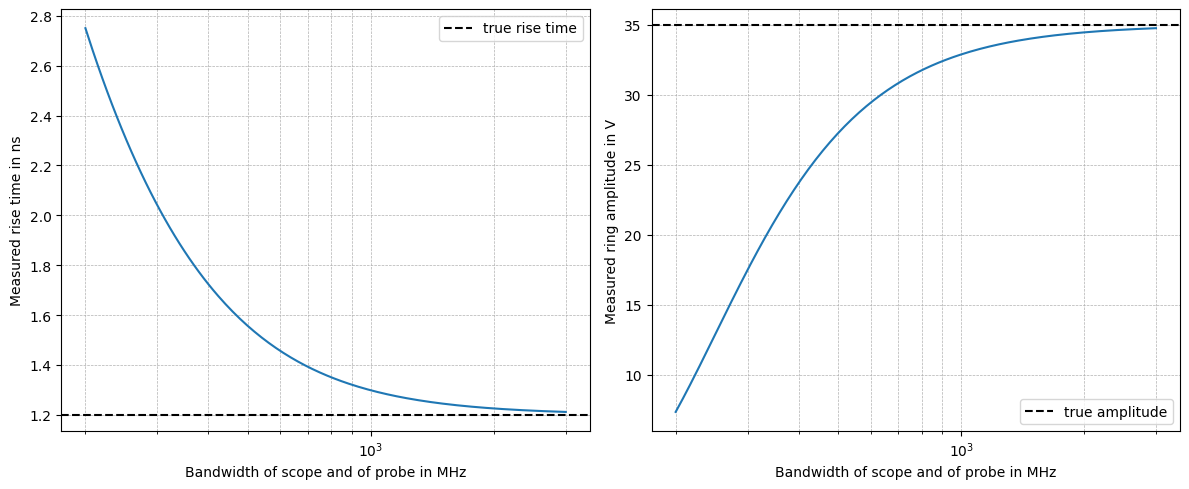

In [2]:
if __name__ == "__main__":
    # Subtask 5.1.2 Rise time and ring amplitude versus bandwidth
    f = np.logspace(np.log10(200e6), np.log10(3e9), 200)
    fig, axs = plt.subplots(1, 2, figsize=(12, 5))
    axs[0].semilogx(f / 1e6, get_tr_meas(t_r_sig, [f, f]) * 1e9)
    axs[0].axhline(t_r_sig * 1e9, color='k', linestyle='--', label='true rise time')
    axs[0].set_ylabel('Measured rise time in ns')
    axs[1].semilogx(f / 1e6, A_ring * get_H_gauss(f_ring, f)**2)
    axs[1].axhline(A_ring, color='k', linestyle='--', label='true amplitude')
    axs[1].set_ylabel('Measured ring amplitude in V')
    for ax in axs:
        ax.set_xlabel('Bandwidth of scope and of probe in MHz')
        ax.grid(True, which='both', linestyle='--', linewidth=0.5)
        ax.legend()
    plt.tight_layout()
    plt.show()


### 5.1.2 Solution

With $500~\mathrm{MHz}$ for scope and probe the edge appears as $1.56~\mathrm{ns}$ (+30 %) and the ring as $27~\mathrm{V}$ instead of $35~\mathrm{V}$. About $770~\mathrm{MHz}$ per stage keeps the amplitude error below 10 %; for the rise time the chain must be about four times faster than the edge.


## 5.2 Ground lead of a passive probe

Switch node: series $R$-$L$-$C$ with $L = 1~\mathrm{nH}$, $C = 280~\mathrm{pF}$, $\zeta = 0.05$, driven by a $48~\mathrm{V}$ ramp of $1~\mathrm{ns}$. Probe: $R_\mathrm{p} = 10~\Omega$ in series with the ground-lead inductance $L_\mathrm{g}$ into $C_\mathrm{p} = 4~\mathrm{pF}$.

5.2.1 Create the function `get_probe(v_node, t, L_g)` that returns the voltage across $C_\mathrm{p}$ (`scipy.signal.lsim`). Plot the true switch-node voltage and the probe voltage for $L_\mathrm{g} = 160$, $50$ and $5~\mathrm{nH}$.

5.2.2 Print the resonance frequency and quality factor of the probe circuit for each $L_\mathrm{g}$, and the peak voltage that each probe shows.


L_g = 160 nH: f_p = 199 MHz, Q = 20.0, peak shown 129.1 V (true 83.2 V)
L_g = 50 nH: f_p = 356 MHz, Q = 11.2, peak shown 164.2 V (true 83.2 V)
L_g = 5 nH: f_p = 1125 MHz, Q = 3.5, peak shown 85.7 V (true 83.2 V)


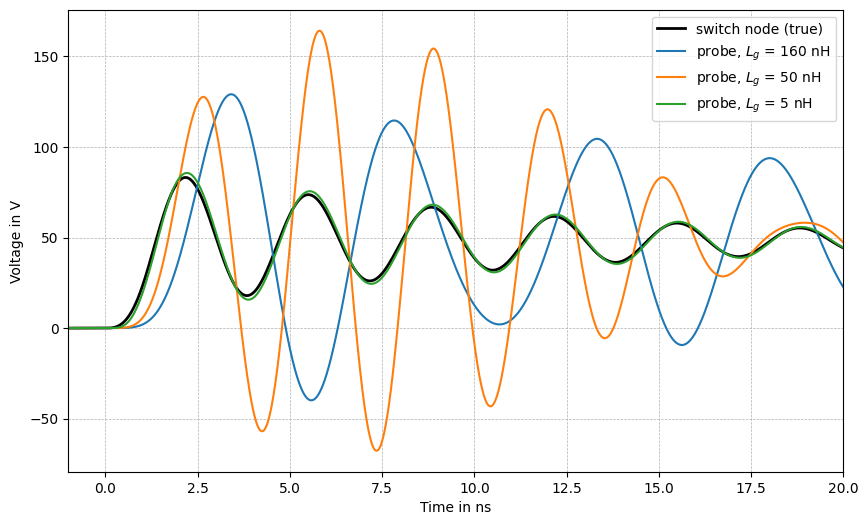

In [3]:
# Subtask 5.2.1 Switch node and probe
L_n, C_n, zeta_n = 1e-9, 280e-12, 0.05
R_n = 2 * zeta_n * np.sqrt(L_n / C_n)
t = np.linspace(-2e-9, 30e-9, 16001)
u = np.clip(t / 1e-9, 0, 1) * 48.0
_, v_node, _ = signal.lsim(signal.TransferFunction([1], [L_n * C_n, R_n * C_n, 1]), U=u, T=t - t[0])
C_p, R_p = 4e-12, 10.0


def get_probe(v_node, t, L_g):
    """Voltage across the probe capacitance for a ground lead L_g."""
    sys = signal.TransferFunction([1], [L_g * C_p, R_p * C_p, 1])
    _, y, _ = signal.lsim(sys, U=v_node, T=t - t[0])
    return y


if __name__ == "__main__":
    plt.figure(figsize=(10, 6))
    plt.plot(t * 1e9, v_node, 'k', linewidth=2, label='switch node (true)')
    for L_g in [160e-9, 50e-9, 5e-9]:
        v_p = get_probe(v_node, t, L_g)
        # Subtask 5.2.2 Resonance, quality factor and peak
        f_p = 1 / (2 * np.pi * np.sqrt(L_g * C_p))
        print(f"L_g = {L_g*1e9:.0f} nH: f_p = {f_p/1e6:.0f} MHz, Q = {np.sqrt(L_g / C_p) / R_p:.1f}, "
              f"peak shown {v_p.max():.1f} V (true {v_node.max():.1f} V)")
        plt.plot(t * 1e9, v_p, label=f'probe, $L_g$ = {L_g*1e9:.0f} nH')
    plt.xlabel('Time in ns')
    plt.ylabel('Voltage in V')
    plt.xlim(-1, 20)
    plt.grid(True, which='both', linestyle='--', linewidth=0.5)
    plt.legend()
    plt.show()


### 5.2.2 Solution

The true switch node peaks at $83~\mathrm{V}$ and rings at $301~\mathrm{MHz}$. With $160~\mathrm{nH}$ the probe circuit resonates at $199~\mathrm{MHz}$ ($Q = 20$) and with $50~\mathrm{nH}$ at $356~\mathrm{MHz}$ ($Q = 11$): the displayed peak and ring frequency are wrong. With a $5~\mathrm{nH}$ spring tip ($1.1~\mathrm{GHz}$) the probe follows the switch node. (Without the bandwidth limit of the scope; compare Task 5.1.)


## 5.3 Current measurement with a shunt

5.3.1 A $10~\mathrm{m\Omega}$ shunt with $L_\mathrm{s} = 0.2~\mathrm{nH}$ carries a current that rises from 0 to $10~\mathrm{A}$ in $1~\mathrm{ns}$ (cosine-shaped edge). Compute the shunt voltage $R i + L_\mathrm{s}\,\mathrm{d}i/\mathrm{d}t$ and the current it indicates, without compensation and with an RC filter $R_\mathrm{f} C_\mathrm{f} = L_\mathrm{s}/R$, and with a filter that is wrong by $\pm 30~\%$. Plot the results.

5.3.2 Compute ring frequency, $Z_0$ and $I Z_0$ for a power loop of $1~\mathrm{nH}$ with $280~\mathrm{pF}$, without and with $6.5~\mathrm{nH}$ of shunt insertion inductance.


no compensation : peak indicated current 319.2 A
compensated     : peak indicated current 10.0 A
filter -30 %    : peak indicated current 14.1 A
filter +30 %    : peak indicated current 8.1 A


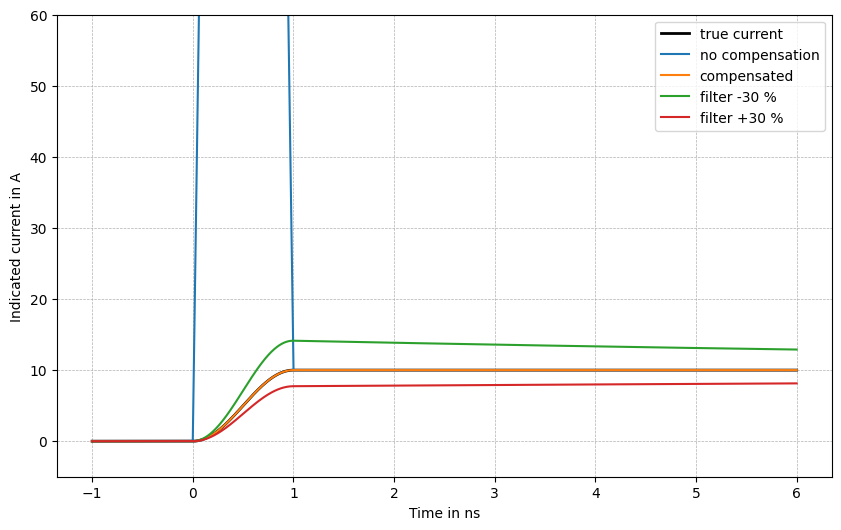

L_loop = 1.0 nH: f_r = 301 MHz, Z0 = 1.89 Ohm, I*Z0 = 18.9 V
L_loop = 7.5 nH: f_r = 110 MHz, Z0 = 5.18 Ohm, I*Z0 = 51.8 V


In [4]:
# Subtask 5.3.1 Shunt with sense-loop inductance
R_sh, L_s = 0.01, 0.2e-9
t3 = np.linspace(-1e-9, 6e-9, 7001)
i_true = 10 * (0.5 - 0.5 * np.cos(np.pi * np.clip(t3 / 1e-9, 0, 1)))
v_sh = R_sh * i_true + L_s * np.gradient(i_true, t3)


def get_rc_filter(v, t, tau_f):
    """First-order RC low-pass with time constant tau_f."""
    if tau_f == 0:
        return v
    _, y, _ = signal.lsim(signal.TransferFunction([1], [tau_f, 1]), U=v, T=t - t[0])
    return y


if __name__ == "__main__":
    plt.figure(figsize=(10, 6))
    plt.plot(t3 * 1e9, i_true, 'k', linewidth=2, label='true current')
    for tau_f, text in [(0, 'no compensation'), (L_s / R_sh, 'compensated'),
                        (0.7 * L_s / R_sh, 'filter -30 %'), (1.3 * L_s / R_sh, 'filter +30 %')]:
        i_ind = get_rc_filter(v_sh, t3, tau_f) / R_sh
        print(f"{text:16s}: peak indicated current {i_ind.max():.1f} A")
        plt.plot(t3 * 1e9, i_ind, label=text)
    plt.ylim(-5, 60)
    plt.xlabel('Time in ns')
    plt.ylabel('Indicated current in A')
    plt.grid(True, which='both', linestyle='--', linewidth=0.5)
    plt.legend()
    plt.show()

# Subtask 5.3.2 Insertion inductance
for L_x in [0, 6.5e-9]:
    L_tot = 1e-9 + L_x
    Z_0 = np.sqrt(L_tot / 280e-12)
    print(f"L_loop = {L_tot*1e9:.1f} nH: f_r = {1/(2*np.pi*np.sqrt(L_tot*280e-12))/1e6:.0f} MHz, "
          f"Z0 = {Z_0:.2f} Ohm, I*Z0 = {10*Z_0:.1f} V")


### 5.3.2 Solution

Without compensation the $0.2~\mathrm{nH}$ sense loop makes the shunt indicate a spike of about $320~\mathrm{A}$ during the edge ($\tau = L_\mathrm{s}/R = 20~\mathrm{ns}$; the cosine-shaped edge is $\pi/2$ times steeper at its centre than the average $10~\mathrm{A/ns}$, which alone gives $200~\mathrm{A}$). The matched filter restores the current. A filter time constant $30~\%$ too short shows $14~\mathrm{A}$ after the edge, one $30~\%$ too long $7.7~\mathrm{A}$; both settle with the filter time constant ($14$ or $26~\mathrm{ns}$), which looks like a real current tail. A coaxial shunt with $6.5~\mathrm{nH}$ insertion inductance lowers the ring frequency from $301$ to $110~\mathrm{MHz}$ and raises $I Z_0$ from $18.9$ to $51.8~\mathrm{V}$.


## 5.4 Deskew of double-pulse data

The file `dpt_turn_on.csv` (columns `t_ns`, `v_ds_V`, `i_d_A`; synthetic data) contains the turn-on of a low-side GaN transistor at $48~\mathrm{V}$ and $10~\mathrm{A}$.

5.4.1 Load the data and plot $v_\mathrm{DS}$ and $i_\mathrm{D}$.

5.4.2 Find the window of the voltage dip during the current rise (from the first drop of $3~\mathrm{V}$ below the initial voltage to the local maximum after the dip). Compute $\Phi(t) = \int (V_0 - v_\mathrm{DS})\,\mathrm{d}t$ in this window and fit $\Phi = a + L_\mathrm{loop}\, i_\mathrm{D}(t + \tau)$ for shifts $\tau$ in the range [$-3 \ldots 3~\mathrm{ns}$]. Keep the $\tau$ with the smallest residual and positive $L_\mathrm{loop}$.

5.4.3 Compute $E_\mathrm{on} = \int v_\mathrm{DS} i_\mathrm{D}\,\mathrm{d}t$ over $-2 \ldots 6~\mathrm{ns}$ for the raw and the deskewed data, and plot $E_\mathrm{on}$ versus the shift.


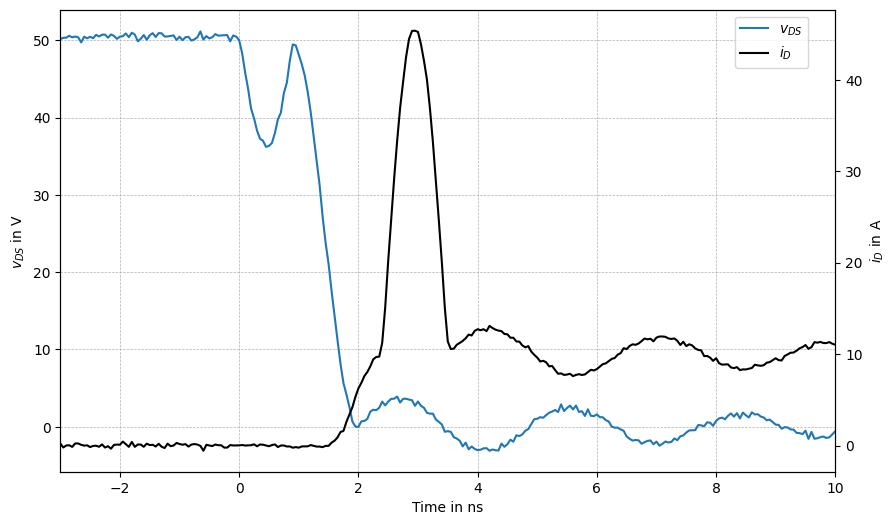

In [5]:
# Subtask 5.4.1 Load and plot the double-pulse data
data = np.loadtxt('dpt_turn_on.csv', delimiter=',', skiprows=1)
t4, v4, i4 = data[:, 0] * 1e-9, data[:, 1], data[:, 2]
dt4 = t4[1] - t4[0]

if __name__ == "__main__":
    fig, ax1 = plt.subplots(figsize=(10, 6))
    ax1.plot(t4 * 1e9, v4, label='$v_{DS}$')
    ax1.set_xlabel('Time in ns')
    ax1.set_ylabel('$v_{DS}$ in V')
    ax2 = ax1.twinx()
    ax2.plot(t4 * 1e9, i4, 'k', label='$i_D$')
    ax2.set_ylabel('$i_D$ in A')
    ax1.set_xlim(-3, 10)
    ax1.grid(True, which='both', linestyle='--', linewidth=0.5)
    fig.legend(loc='upper right', bbox_to_anchor=(0.88, 0.88))
    plt.show()


In [6]:
# Subtask 5.4.2 Deskew with the integrated voltage dip


def smooth(x, n=7):
    return np.convolve(x, np.ones(n) / n, mode='same')


v_s = smooth(v4)
V_0 = np.mean(v4[(t4 > -8e-9) & (t4 < -2e-9)])
k0 = np.argmax(t4 > -5e-9)
k1 = k0 + np.argmax(v_s[k0:] < V_0 - 3)          # start of the dip
k_min, k = k1, k1
while v_s[k] < v_s[k_min] + 2.0:                 # first local minimum
    if v_s[k] < v_s[k_min]:
        k_min = k
    k += 1
k2 = k_min + np.argmax(v_s[k_min:k + 10])         # local maximum after the dip
win = slice(k1 - 20, k2 + 1)
phi = np.cumsum(V_0 - v4[win]) * dt4
best = None
for tau in np.arange(-3e-9, 3e-9 + 1e-12, 0.01e-9):
    i_shift = np.interp(t4 + tau, t4, i4)[win]
    A = np.column_stack([np.ones(i_shift.size), i_shift])
    coef, *_ = np.linalg.lstsq(A, phi, rcond=None)
    res = np.sum((A @ coef - phi)**2)
    if coef[1] > 0 and (best is None or res < best[0]):
        best = (res, tau, coef[1])
_, tau_best, L_loop_fit = best
print(f"dip window {t4[k1]*1e9:.2f} ... {t4[k2]*1e9:.2f} ns, skew {tau_best*1e9:.2f} ns, "
      f"L_loop = {L_loop_fit*1e9:.2f} nH")


dip window 0.05 ... 0.95 ns, skew 1.45 ns, L_loop = 0.85 nH


E_on raw 0.09 uJ, deskewed 1.02 uJ


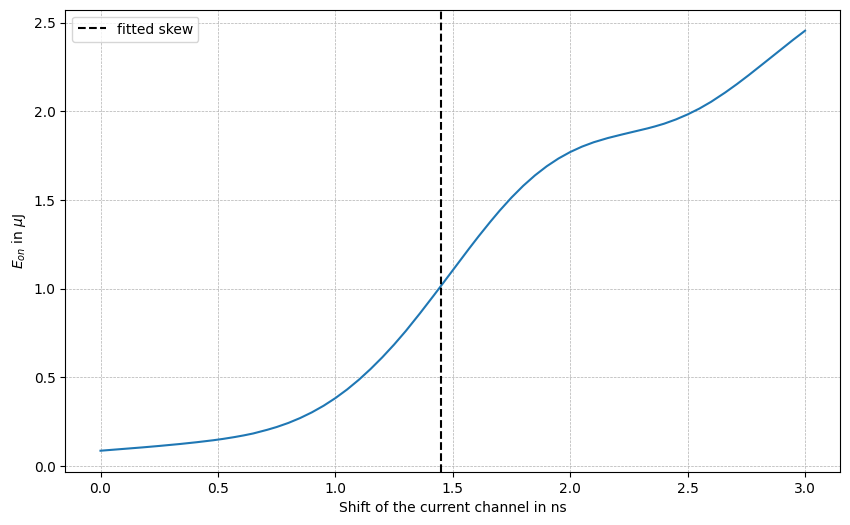

In [7]:
# Subtask 5.4.3 Turn-on energy before and after deskew
k_E = (t4 > -2e-9) & (t4 < 6e-9)


def get_E_on(tau):
    i_shift = np.interp(t4 + tau, t4, i4)
    return np.trapezoid(v4[k_E] * i_shift[k_E], t4[k_E])


print(f"E_on raw {get_E_on(0)*1e6:.2f} uJ, deskewed {get_E_on(tau_best)*1e6:.2f} uJ")
if __name__ == "__main__":
    taus = np.linspace(0, 3e-9, 301)
    plt.figure(figsize=(10, 6))
    plt.plot(taus * 1e9, [get_E_on(x) * 1e6 for x in taus])
    plt.axvline(tau_best * 1e9, color='k', linestyle='--', label='fitted skew')
    plt.xlabel('Shift of the current channel in ns')
    plt.ylabel('$E_{on}$ in $\\mu$J')
    plt.grid(True, which='both', linestyle='--', linewidth=0.5)
    plt.legend()
    plt.show()


### 5.4.3 Solution

The voltage dip starts at $t \approx 0$, the current rise about $1.5~\mathrm{ns}$ later. The fit gives a skew of $1.45~\mathrm{ns}$ and $L_\mathrm{loop} \approx 0.85~\mathrm{nH}$ (the data were generated with $1.5~\mathrm{ns}$ and $0.8~\mathrm{nH}$). $E_\mathrm{on}$ rises from $0.09~\mu\mathrm{J}$ (raw) to $1.02~\mu\mathrm{J}$; the correct value of the data is $1.10~\mu\mathrm{J}$. The slope of the curve, about $0.09~\mu\mathrm{J}$ per $50~\mathrm{ps}$, shows how precisely the channels must be aligned.


## 5.5 Efficiency and loss

5.5.1 Create the function `get_loss_uncertainty(P_out, eta, acc_rdg, acc_rng, P_range)` that returns the loss and its worst-case and RSS uncertainty. Evaluate it for $100~\mathrm{W}$, $97.5~\%$, $\pm(0.05~\% + 0.05~\%~\mathrm{of}~150~\mathrm{W})$.

5.5.2 Check the RSS value with a Monte-Carlo simulation (uniformly distributed errors within the specification; RSS of uniform errors corresponds to about 58 % of the limits, so compare standard deviations).

5.5.3 Plot the relative uncertainty of the loss versus efficiency in the range [$90 \ldots 99.5~\%$] for the given instrument and for $\pm 0.1~\%$ of reading.


In [8]:
# Subtask 5.5.1 Uncertainty of the loss


def get_loss_uncertainty(P_out, eta, acc_rdg, acc_rng, P_range):
    """Loss in W and its worst-case and RSS uncertainty in W."""
    P_in = P_out / eta
    d_in = acc_rdg * P_in + acc_rng * P_range
    d_out = acc_rdg * P_out + acc_rng * P_range
    return P_in - P_out, d_in + d_out, np.hypot(d_in, d_out)


P_loss, d_wc, d_rss = get_loss_uncertainty(100, 0.975, 0.0005, 0.0005, 150)
print(f"loss {P_loss:.3f} W, worst case +-{d_wc:.3f} W ({d_wc/P_loss*100:.1f} %), "
      f"RSS +-{d_rss:.3f} W ({d_rss/P_loss*100:.1f} %)")

# Subtask 5.5.2 Monte-Carlo check with uniformly distributed errors
rng = np.random.default_rng(1)
n = 200000
P_in = 100 / 0.975
e_in = rng.uniform(-1, 1, n) * (0.0005 * P_in + 0.0005 * 150)
e_out = rng.uniform(-1, 1, n) * (0.0005 * 100 + 0.0005 * 150)
loss_mc = (P_in + e_in) - (100 + e_out)
print(f"Monte Carlo: std {loss_mc.std():.4f} W, RSS of the uniform standard deviations "
      f"{d_rss/np.sqrt(3):.4f} W, largest deviation {np.abs(loss_mc - P_loss).max():.3f} W")


loss 2.564 W, worst case +-0.251 W (9.8 %), RSS +-0.178 W (6.9 %)
Monte Carlo: std 0.1026 W, RSS of the uniform standard deviations 0.1026 W, largest deviation 0.251 W


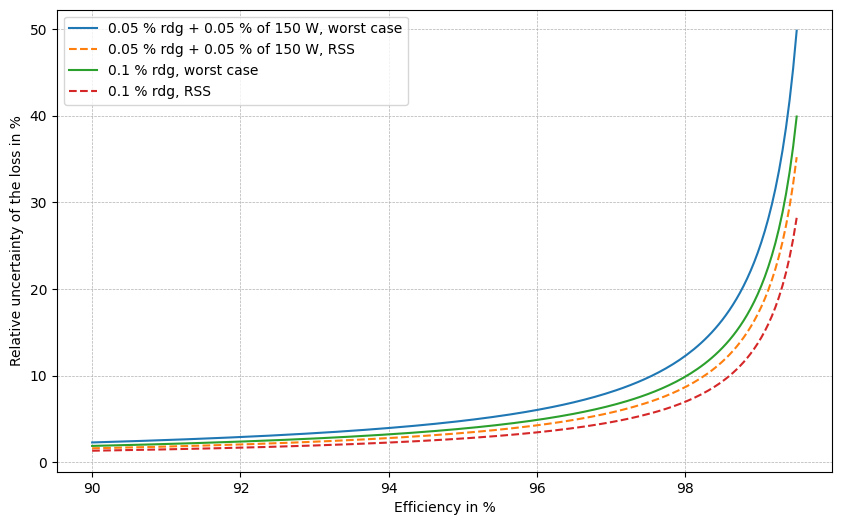

In [9]:
if __name__ == "__main__":
    # Subtask 5.5.3 Relative uncertainty versus efficiency
    eta = np.linspace(0.90, 0.995, 200)
    plt.figure(figsize=(10, 6))
    for (a_rdg, a_rng, text) in [(0.0005, 0.0005, '0.05 % rdg + 0.05 % of 150 W'), (0.001, 0, '0.1 % rdg')]:
        P_loss, d_wc, d_rss = get_loss_uncertainty(100, eta, a_rdg, a_rng, 150)
        plt.plot(eta * 100, d_wc / P_loss * 100, label=f'{text}, worst case')
        plt.plot(eta * 100, d_rss / P_loss * 100, '--', label=f'{text}, RSS')
    plt.xlabel('Efficiency in %')
    plt.ylabel('Relative uncertainty of the loss in %')
    plt.grid(True, which='both', linestyle='--', linewidth=0.5)
    plt.legend()
    plt.show()


### 5.5.3 Solution

The loss of $2.56~\mathrm{W}$ is uncertain by $\pm 0.25~\mathrm{W}$ (worst case, 9.8 %) or $\pm 0.18~\mathrm{W}$ (RSS, 6.9 %). The Monte-Carlo standard deviation equals the RSS of the standard deviations of uniform errors ($\pm$limit$/\sqrt{3}$). The relative uncertainty grows with $1/(1-\eta)$: above about 98 % the electrical method cannot resolve design changes of a few percent of the loss.


## 5.6 Core loss at 10 MHz

5.6.1 Create the function `get_resonant_q(f, L, v_in, v_out, R_C, R_cu, V_core)` that returns $Q$, $R_\mathrm{core}$, $\hat{\imath}$, $P_\mathrm{core}$ and the loss density. Evaluate it for $f = 10~\mathrm{MHz}$, $L = 1~\mu\mathrm{H}$, $\hat{v}_\mathrm{in} = 0.2~\mathrm{V}$, $\hat{v}_\mathrm{out} = 30~\mathrm{V}$, $R_\mathrm{C} = 0.01~\Omega$, $R_\mathrm{cu} = 0.15~\Omega$, $0.1~\mathrm{cm^3}$.

5.6.2 Plot the relative error of the two-winding method, $Q_\mathrm{core}\,\Delta\varphi$, versus the skew in the range [$1 \ldots 1000~\mathrm{ps}$] at $10~\mathrm{MHz}$ for $Q_\mathrm{core} = 50$, $100$ and the value of 5.6.1 (log axes).


In [10]:
# Subtask 5.6.1 Resonant Q method


def get_resonant_q(f, L, v_in, v_out, R_C, R_cu, V_core):
    """Q, R_core in Ohm, peak current in A, core loss in W and loss density in W/m^3."""
    w = 2 * np.pi * f
    Q = v_out / v_in
    R_core = w * L * v_in / v_out - R_C - R_cu
    C = 1 / (w**2 * L)
    i_pk = v_out * w * C
    P = 0.5 * i_pk**2 * R_core
    return Q, R_core, i_pk, P, P / V_core


Q, R_core, i_pk, P_core, P_V = get_resonant_q(10e6, 1e-6, 0.2, 30, 0.01, 0.15, 0.1e-6)
Q_core = 2 * np.pi * 10e6 * 1e-6 / R_core
print(f"Q = {Q:.0f}, R_core = {R_core:.3f} Ohm, i_pk = {i_pk:.3f} A, P_core = {P_core*1e3:.1f} mW, "
      f"P_V = {P_V/1e3:.0f} kW/m^3 = {P_V/1e6*1e3:.0f} mW/cm^3, Q_core = {Q_core:.0f}")


Q = 150, R_core = 0.259 Ohm, i_pk = 0.477 A, P_core = 29.5 mW, P_V = 295 kW/m^3 = 295 mW/cm^3, Q_core = 243


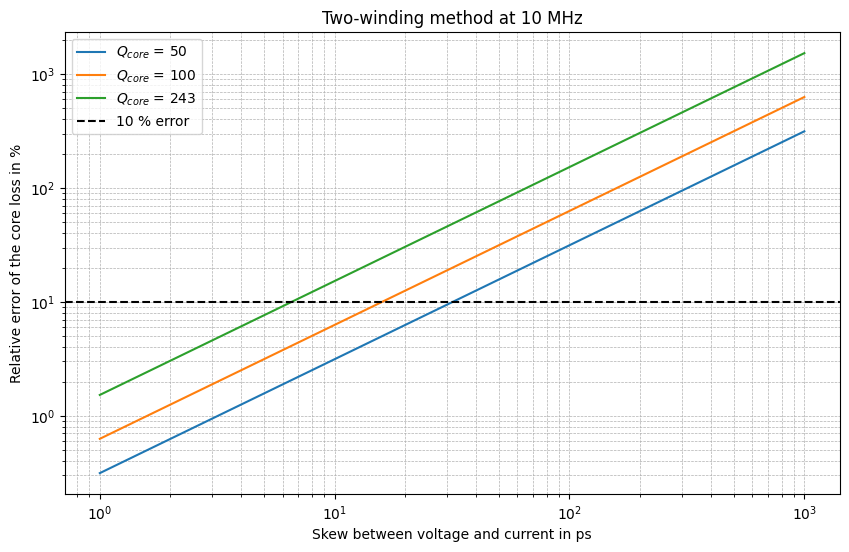

In [11]:
if __name__ == "__main__":
    # Subtask 5.6.2 Phase-error sensitivity of the two-winding method
    skew = np.logspace(-12, -9, 200)
    plt.figure(figsize=(10, 6))
    for Qc in [50, 100, Q_core]:
        plt.loglog(skew * 1e12, Qc * 2 * np.pi * 10e6 * skew * 100, label=f'$Q_{{core}}$ = {Qc:.0f}')
    plt.axhline(10, color='k', linestyle='--', label='10 % error')
    plt.xlabel('Skew between voltage and current in ps')
    plt.ylabel('Relative error of the core loss in %')
    plt.title('Two-winding method at 10 MHz')
    plt.grid(True, which='both', linestyle='--', linewidth=0.5)
    plt.legend()
    plt.show()


### 5.6.2 Solution

$Q = 150$, $R_\mathrm{core} = 0.259~\Omega$, $\hat{\imath} = 0.477~\mathrm{A}$, $P_\mathrm{core} = 29.5~\mathrm{mW}$ or $295~\mathrm{mW/cm^3}$. The core alone has $Q_\mathrm{core} = 243$: a skew of $100~\mathrm{ps}$ gives 150 % error in the two-winding method, and 10 % would need less than $7~\mathrm{ps}$. The resonant method needs only two amplitudes and no phase.
